# Midterm Project: ResNet Autoencoder
This notebook explores an encoder-decoder architecture based on
ResNet50 and ResNet101 using the ImageNette dataset.

# Part 1 — Setup and dataset

In [180]:
import os
import sys
import time
import random
import gc

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms


print("PyTorch version:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0
MPS available: True
CUDA available: False


### 1.1 Experiment Configuration

The experiment begins with a small training configuration to
verify that the complete training pipeline works.

In [181]:
SEED = 42

EPOCHS = 4
MAX_TRAIN = 2000
MAX_VAL = 200
BATCH_SIZE = 2
LEARNING_RATE = 0.0001
IMAGE_SIZE = 221

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

PROJECT_DIR = Path.cwd()

REPO_DIR = PROJECT_DIR / "ResNet-decoder-main"

# Change this path only if your ImageNette folder is elsewhere.
DATA_DIR = (
    Path.home()
    / "Desktop"
    / "Rowan Fall 2026"
    / "ADV Models Of Deep Learning"
    / "git"
    / "imagenette2-160"
)

RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Project directory:", PROJECT_DIR)
print("Repository found:", REPO_DIR.exists())
print("Dataset found:", DATA_DIR.exists())

Device: mps
Project directory: /Users/mozart/Desktop/Rowan Fall 2026/ADV Models Of Deep Learning/MidTerm Project
Repository found: True
Dataset found: True


In [182]:
from pathlib import Path
import sys

# Add the ResNet repository to Python's import path
REPO_DIR = Path.cwd() / "ResNet-decoder-main"

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

import res_encoder as enc
import res_decoder as dec

print("Encoder imported successfully.")
print("Decoder imported successfully.")

Encoder imported successfully.
Decoder imported successfully.


### 1.2  ImageNette Dataset Preparation
ImageNette is a smaller image classification dataset containing 10 classes selected from ImageNet.

In [183]:
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

train_path = DATA_DIR / "train"
val_path = DATA_DIR / "val"

if not train_path.exists() or not val_path.exists():
    raise FileNotFoundError(
        "ImageNette train/val folders not found. Check DATA_DIR."
    )

train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=transform
)

val_dataset = datasets.ImageFolder(
    root=val_path,
    transform=transform
)

train_indices = random.Random(SEED).sample(
    range(len(train_dataset)),
    min(MAX_TRAIN, len(train_dataset))
)

val_indices = random.Random(SEED).sample(
    range(len(val_dataset)),
    min(MAX_VAL, len(val_dataset))
)

train_subset = Subset(train_dataset, train_indices)
val_subset = Subset(val_dataset, val_indices)

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Full training dataset:", len(train_dataset))
print("Full validation dataset:", len(val_dataset))
print("Training images selected:", len(train_subset))
print("Validation images selected:", len(val_subset))
print("Number of classes:", len(train_dataset.classes))

Full training dataset: 9469
Full validation dataset: 3925
Training images selected: 2000
Validation images selected: 200
Number of classes: 10


### 1.3 Display sample images

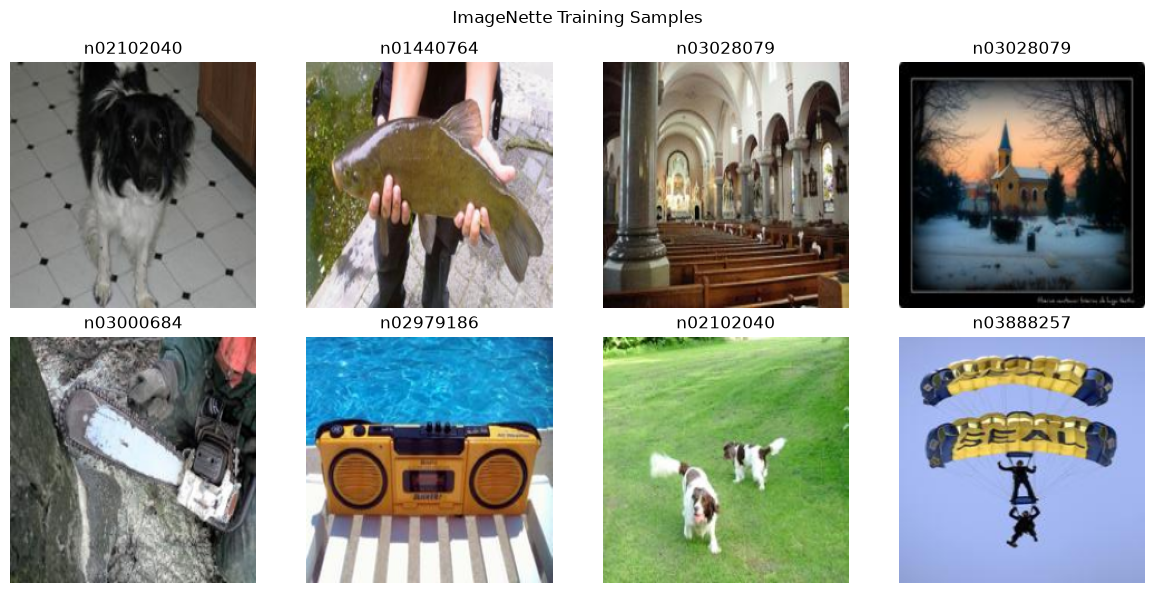

In [212]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, index in zip(axes.flat, range(8)):
    image, label = train_subset[index]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(train_dataset.classes[label])
    ax.axis("off")

plt.suptitle("ImageNette Training Samples")
plt.tight_layout()
plt.show()

# Part 2 — Build and test the ResNet autoencoder

### 2.1 ResNet Encoder-Decoder Architecture
An autoencoder contains two main components:
**Encoder:** Converts an input image into a compressed feature
representation.
**Decoder:** Uses the compressed features to reconstruct an image.

In [185]:
def create_autoencoder(depth=50):

    if depth == 50:
        encoder_layers = [3, 4, 6, 3]
        decoder_layers = [3, 6, 4, 3]

    elif depth == 101:
        encoder_layers = [3, 4, 23, 3]
        decoder_layers = [3, 23, 4, 3]

    else:
        raise ValueError("Depth must be 50 or 101.")

    encoder = enc.ResNet(
        enc.Bottleneck,
        encoder_layers,
        return_indices=True
    ).to(DEVICE)

    decoder = dec.ResNet(
        dec.Bottleneck,
        decoder_layers
    ).to(DEVICE)

    # Preserve spatial information
    encoder.avgpool = nn.Identity()
    decoder.unsample = nn.Identity()

    # Keep reconstructed pixels between 0 and 1
    decoder.relu = nn.Sigmoid()

    return encoder, decoder

### 2.2 Test input and output shapes

In [186]:
encoder, decoder = create_autoencoder(depth=50)

encoder.eval()
decoder.eval()

images, labels = next(iter(train_loader))
images = images.to(DEVICE)

with torch.no_grad():
    features, indices = encoder(images)
    reconstructed = decoder(features, indices)

print("Input shape:", tuple(images.shape))
print("Encoded feature shape:", tuple(features.shape))
print("Reconstructed shape:", tuple(reconstructed.shape))

print("Input pixel range:",
      images.min().item(),
      images.max().item())

print("Output value range:",
      reconstructed.min().item(),
      reconstructed.max().item())

assert reconstructed.shape == images.shape

print("Forward-pass test successful.")

Input shape: (2, 3, 221, 221)
Encoded feature shape: (2, 2048, 7, 7)
Reconstructed shape: (2, 3, 221, 221)
Input pixel range: 0.0 1.0
Output value range: 0.155853733420372 0.8592303395271301
Forward-pass test successful.


### 2.3 Reconstruction Loss
The autoencoder learns by comparing the reconstructed image with the original input image.

This experiment uses Mean Squared Error (MSE).


### 2.4 Connection to Course Material
- This project connects to several topics covered in class, including tensors, neural networks, activation functions, loss functions, and optimization.

- The ImageNette images are converted into PyTorch tensors before being processed by the model. The ResNet encoder extracts features from the images, and the decoder uses those features to reconstruct the original images.

- The model uses Mean Squared Error (MSE) to measure the difference between the original and reconstructed images. During training, backpropagation calculates gradients, and the Adam optimizer updates the model's parameters to reduce the reconstruction error.

- Comparing ResNet50 and ResNet101 also helped me understand how network depth affects performance. In my experiment, ResNet50 achieved a lower MSE than ResNet101, showing that a deeper model does not always produce better results.

- The ablation study helped me understand the importance of preserving spatial information and choosing an appropriate activation function. Keeping the 7 × 7 feature maps and using Sigmoid produced the lowest reconstruction error among the four configurations tested.

# Part 3 — Train and evaluate

### 3.1 Training function

In [187]:
def train_one_epoch(encoder, decoder, loader, optimizer, criterion):

    encoder.train()
    decoder.train()

    total_loss = 0.0
    total_images = 0

    for images, _ in loader:

        images = images.to(DEVICE)

        optimizer.zero_grad()

        features, indices = encoder(images)
        outputs = decoder(features, indices)

        loss = criterion(outputs, images)

        loss.backward()
        optimizer.step()

        batch_size = images.size(0)

        total_loss += loss.item() * batch_size
        total_images += batch_size

    return total_loss / total_images

### 3.2 Validation function

In [188]:
def validate(encoder, decoder, loader, criterion):

    encoder.eval()
    decoder.eval()

    total_loss = 0.0
    total_images = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(DEVICE)

            features, indices = encoder(images)
            outputs = decoder(features, indices)

            loss = criterion(outputs, images)

            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            total_images += batch_size

    return total_loss / total_images

### 3.3 Training 

In [189]:
def run_experiment(depth, epochs=EPOCHS):

    print(f"\nTraining ResNet{depth} Autoencoder")

    torch.manual_seed(SEED)

    encoder, decoder = create_autoencoder(depth)

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        list(encoder.parameters()) + list(decoder.parameters()),
        lr=LEARNING_RATE
    )

    history = []
    start_time = time.time()

    for epoch in range(epochs):

        train_loss = train_one_epoch(
            encoder,
            decoder,
            train_loader,
            optimizer,
            criterion
        )

        val_loss = validate(
            encoder,
            decoder,
            val_loader,
            criterion
        )

        history.append({
            "model": f"ResNet{depth}",
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Validation MSE: {val_loss:.6f}"
        )

    elapsed = time.time() - start_time

    torch.save(
        encoder.state_dict(),
        RESULTS_DIR / f"resnet{depth}_encoder.pth"
    )

    torch.save(
        decoder.state_dict(),
        RESULTS_DIR / f"resnet{depth}_decoder.pth"
    )

    print(f"Training completed in {elapsed / 60:.2f} minutes")

    return encoder, decoder, pd.DataFrame(history), elapsed

### 3.4 Train ResNet50

In [190]:
del encoder, decoder
gc.collect()

if DEVICE.type == "mps":
    torch.mps.empty_cache()
elif DEVICE.type == "cuda":
    torch.cuda.empty_cache()

encoder50, decoder50, history50, time50 = run_experiment(
    depth=50
)

display(history50)


Training ResNet50 Autoencoder
Epoch 1/4 | Train MSE: 0.057693 | Validation MSE: 0.036221
Epoch 2/4 | Train MSE: 0.033604 | Validation MSE: 0.018078
Epoch 3/4 | Train MSE: 0.027737 | Validation MSE: 0.018200
Epoch 4/4 | Train MSE: 0.024642 | Validation MSE: 0.012847
Training completed in 11.24 minutes


,model,epoch,train_loss,val_loss
0,ResNet50,1,0.057693,0.036221
1,ResNet50,2,0.033604,0.018078
2,ResNet50,3,0.027737,0.018200
3,ResNet50,4,0.024642,0.012847


### 3.5 Reconstruction Evaluation

The model is evaluated using validation images that are separate from the selected training images.

Two reconstruction metrics are calculated:
**Mean Squared Error (MSE)**
Measures the average squared pixel reconstruction error. Lower values indicate smaller reconstruction differences.

**Peak Signal-to-Noise Ratio (PSNR)**
Measures reconstruction quality using the ratio between the maximum pixel value and the reconstruction error.

### 3.6 Calculate MSE and PSNR

In [191]:
def evaluate_model(encoder, decoder, loader):

    encoder.eval()
    decoder.eval()

    total_squared_error = 0.0
    total_pixels = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(DEVICE)

            features, indices = encoder(images)
            outputs = decoder(features, indices)

            total_squared_error += (
                (outputs - images) ** 2
            ).sum().item()

            total_pixels += images.numel()

    mse = total_squared_error / total_pixels

    psnr = (
        10 * np.log10(1.0 / mse)
        if mse > 0
        else float("inf")
    )

    return mse, psnr


mse50, psnr50 = evaluate_model(
    encoder50,
    decoder50,
    val_loader
)

print(f"ResNet50 MSE: {mse50:.6f}")
print(f"ResNet50 PSNR: {psnr50:.2f} dB")

ResNet50 MSE: 0.012848
ResNet50 PSNR: 18.91 dB


### 3.7 Display original and reconstructed images

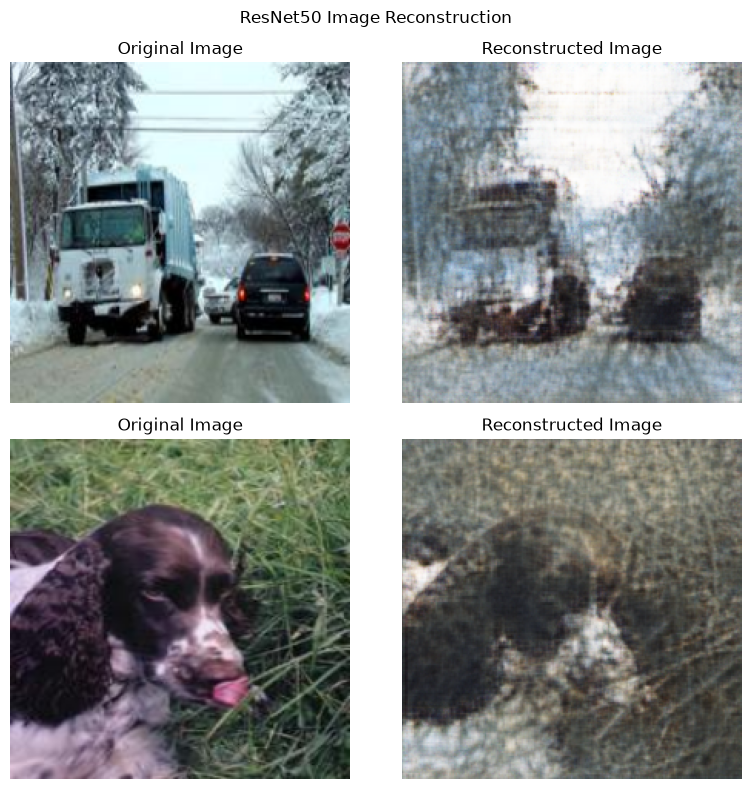

In [192]:
def show_reconstructions(encoder, decoder, loader, title):

    encoder.eval()
    decoder.eval()

    images, _ = next(iter(loader))
    images = images.to(DEVICE)

    with torch.no_grad():
        features, indices = encoder(images)
        outputs = decoder(features, indices)

    originals = images.cpu()
    reconstructions = outputs.cpu()

    count = min(2, len(originals))

    fig, axes = plt.subplots(
        count,
        2,
        figsize=(8, 4 * count),
        squeeze=False
    )

    for i in range(count):

        original = originals[i].permute(1, 2, 0).numpy()
        reconstructed = (
            reconstructions[i]
            .permute(1, 2, 0)
            .numpy()
        )

        axes[i, 0].imshow(original)
        axes[i, 0].set_title("Original Image")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(
            np.clip(reconstructed, 0, 1)
        )
        axes[i, 1].set_title("Reconstructed Image")
        axes[i, 1].axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_reconstructions(
    encoder50,
    decoder50,
    val_loader,
    "ResNet50 Image Reconstruction"
)

### 3.8 Plot ResNet50 training loss

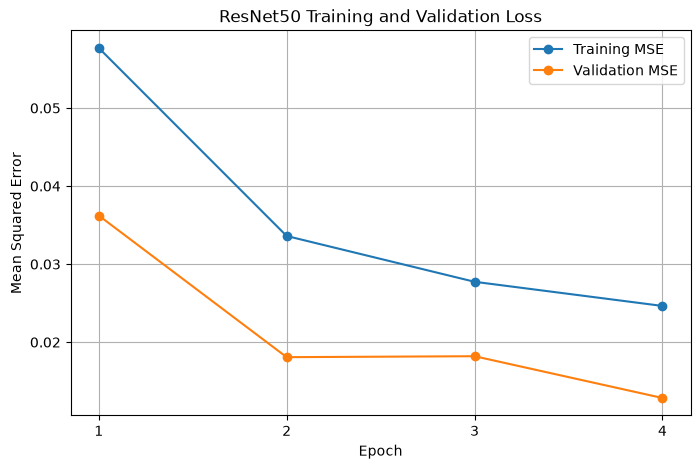

In [193]:
plt.figure(figsize=(8, 5))

plt.plot(
    history50["epoch"],
    history50["train_loss"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    history50["epoch"],
    history50["val_loss"],
    marker="o",
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("ResNet50 Training and Validation Loss")
plt.xticks(history50["epoch"])
plt.legend()
plt.grid(True)
plt.show()

# Part 4 — Compare ResNet50 and ResNet101

### 4.1 Architecture Comparison
This experiment compares two ResNet autoencoder architectures:
- ResNet50
- ResNet101

The main variable being changed is the network depth.

Keeping these settings consistent helps isolate the effect of model depth.
The comparison will examine:
1. Training loss
2. Validation loss
3. Reconstruction MSE
4. Reconstruction PSNR
5. Training time
6. Visual reconstruction quality

Because this initial experiment uses a small dataset subset and four epochs, the results should be treated as preliminary.

In [194]:
del encoder50, decoder50
gc.collect()

if DEVICE.type == "mps":
    torch.mps.empty_cache()
elif DEVICE.type == "cuda":
    torch.cuda.empty_cache()

encoder101, decoder101, history101, time101 = run_experiment(
    depth=101
)

display(history101)


Training ResNet101 Autoencoder
Epoch 1/4 | Train MSE: 0.078222 | Validation MSE: 0.047699
Epoch 2/4 | Train MSE: 0.047495 | Validation MSE: 0.028008
Epoch 3/4 | Train MSE: 0.037603 | Validation MSE: 0.021819
Epoch 4/4 | Train MSE: 0.032286 | Validation MSE: 0.017883
Training completed in 19.85 minutes


,model,epoch,train_loss,val_loss
0,ResNet101,1,0.078222,0.047699
1,ResNet101,2,0.047495,0.028008
2,ResNet101,3,0.037603,0.021819
3,ResNet101,4,0.032286,0.017883


### 4.2 Evaluate ResNet101

ResNet101 MSE: 0.017879
ResNet101 PSNR: 17.48 dB


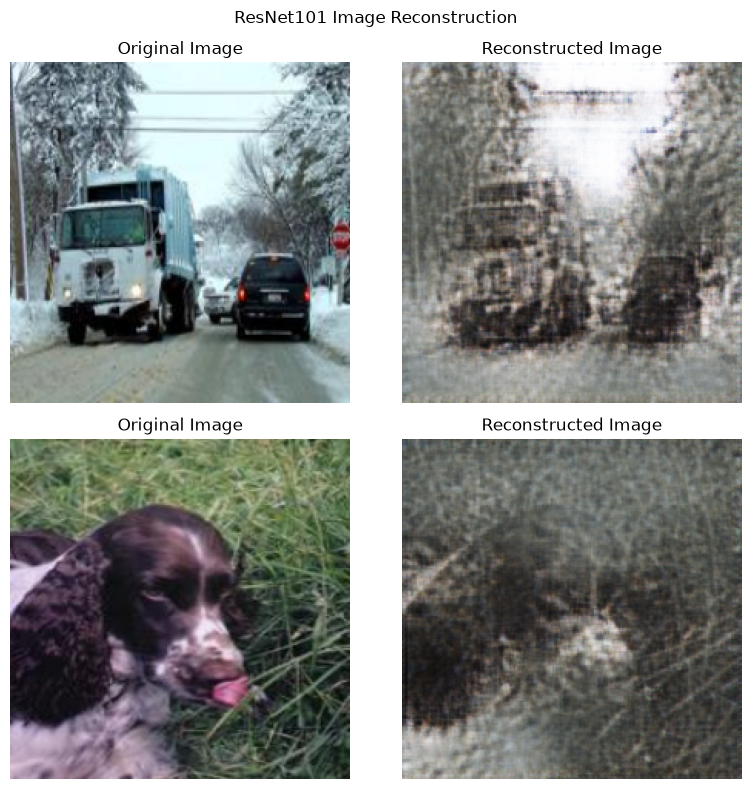

In [195]:
mse101, psnr101 = evaluate_model(
    encoder101,
    decoder101,
    val_loader
)

print(f"ResNet101 MSE: {mse101:.6f}")
print(f"ResNet101 PSNR: {psnr101:.2f} dB")

show_reconstructions(
    encoder101,
    decoder101,
    val_loader,
    "ResNet101 Image Reconstruction"
)

### 4.3 Compare results

In [196]:
comparison = pd.DataFrame([
    {
        "Model": "ResNet50",
        "Epochs": EPOCHS,
        "Training Images": len(train_subset),
        "Validation MSE": mse50,
        "PSNR (dB)": psnr50,
        "Training Time (min)": time50 / 60
    },
    {
        "Model": "ResNet101",
        "Epochs": EPOCHS,
        "Training Images": len(train_subset),
        "Validation MSE": mse101,
        "PSNR (dB)": psnr101,
        "Training Time (min)": time101 / 60
    }
])

display(comparison.round(4))

comparison.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

,Model,Epochs,Training Images,Validation MSE,PSNR (dB),Training Time (min)
0,ResNet50,4,2000,0.0128,18.9117,11.2440
1,ResNet101,4,2000,0.0179,17.4765,19.8511


### 4.4 Compare training curves

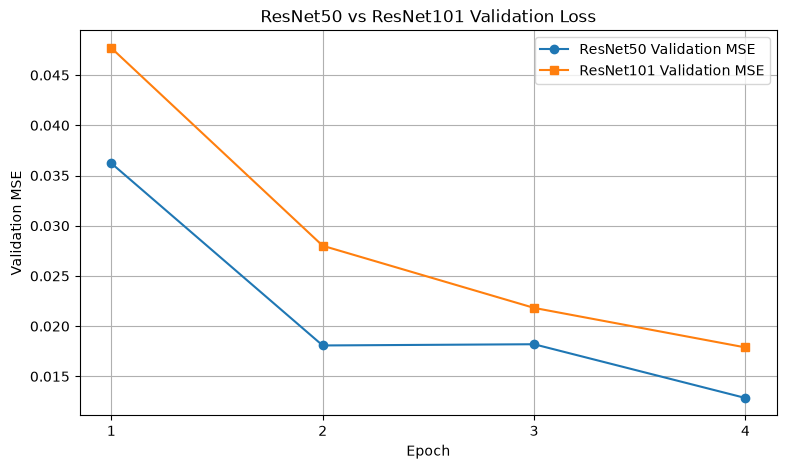

In [197]:
plt.figure(figsize=(9, 5))

plt.plot(
    history50["epoch"],
    history50["val_loss"],
    marker="o",
    label="ResNet50 Validation MSE"
)

plt.plot(
    history101["epoch"],
    history101["val_loss"],
    marker="s",
    label="ResNet101 Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.title("ResNet50 vs ResNet101 Validation Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(True)
plt.show()

### 4.5 Save training history

In [199]:
all_history = pd.concat(
    [history50, history101],
    ignore_index=True
)

display(all_history)

all_history.to_csv(
    RESULTS_DIR / "training_history.csv",
    index=False
)

print("Results saved in:", RESULTS_DIR)

,model,epoch,train_loss,val_loss
0,ResNet50,1,0.057693,0.036221
1,ResNet50,2,0.033604,0.018078
2,ResNet50,3,0.027737,0.018200
3,ResNet50,4,0.024642,0.012847
4,ResNet101,1,0.078222,0.047699
5,ResNet101,2,0.047495,0.028008
6,ResNet101,3,0.037603,0.021819
7,ResNet101,4,0.032286,0.017883


Results saved in: /Users/mozart/Desktop/Rowan Fall 2026/ADV Models Of Deep Learning/MidTerm Project/results


# Part 5 — My observations

### 5.1 Dataset Preparation

- Number of training images: 2000
- Number of validation images: 200 
- Input image dimensions: 3 x 221 x 221 (RGB)
- Observations about the ImageNette images: The dataset has 10 different classes of images. Each image has different objects, baackgrounds, colors, and details. All images were resized to 221 x 221 pixels.

### 5.2 Encoder and Decoder

- ResNet50 encoded feature dimensions: (2, 2048, 7, 7)
- ResNet50 reconstructed image dimensions: (2, 3, 221, 221)
- What information may be lost during compression?
Small deteails, textures, spatial information, and colors may be lost when the image is compreseed.
- How does the decoder attempt to reconstruct the image?
The decoder uses the compressed features and transposed convolution layers to rebuild an image with the original dimensions.

### 5.3 ResNet50 Results

- Final training MSE: 0.024642
- Final validation MSE: 0.012847
- Evaluation MSE: 0.012848
- Reconstruction PSNR: 18.91 dB
- Training time: 11.24 minutes
- What do the reconstructed images look like?
The reconstructed images are moslty gray, blurry, and with some noise. The origial objects are difficult to orgonize, showing that the model did not reconstruct the images accurately after four epochs.

### 5.4 ResNet101 Results

- Final training MSE: 0.032286
- Final validation MSE: 0.017883
- Evaluation MSE: 0.017879
- Reconstruction PSNR: 17.48 dB
- Training time: 19.85 minutes
- What do the reconstructed images look like?
The reconstructed images are mostly gray with noise and very little details. The objects are not recognizable, and the reconstructin quality is worse than ResNet50.

### 5.5 Architecture Comparison

- Which model produced the lower validation MSE?
ResNet50
- Which model produced the higher PSNR?
ResNet50
- Which model required more training time?
ResNet101
- Did the deeper architecture improve reconstruction?
No, Restnet101 had a higher MSE and lower PSNR the experiment.
- Were two epochs sufficient to produce recognizable images?
No, Both models produced blurry, mostly gray reconstructions.

### 5.6 Limitations and Further Experiments

- What limitations were observed?
The original experiment used 2000 training images and four epochs. The reconstructed images had poor details, and the models stuggled to reproduce recognizable objects.
- How might additional training affect the results.
Additional training could help the models learn more image features and improve reconstruction quality, although improvement is not guaranteed,
- How might the 1 × 1 feature bottleneck affect reconstruction?
Compressing the features to 1 x 1 removes much of the spatial information, making it harder for the decoder to reconstruct image details.
- What changes would be useful to test next?
Test a larger training dataset, preserve the 7 x 7 spatial features, train for additoinal epochs, and replace the decoder's final ReLU activation with Sigmoid.

## 5.7 Earlier Improved ResNet50 Experiment

### 5.7.1 Changes Made

- Increased training images from 200 to 2,000.
- Increased validation images from 40 to 200.
- Preserved the encoder's 7 x 7 spatial features instead of compressing them to 1 x 1.
- Replaced the decoder's final ReLU activation with Sigmoid.
- Fine tuned the Sigmoid model for 2 additional epochs after the larger spatial ResNet50 experiment.

### 5.7.2 Final Results

- Training images: 2,000
- Validation images: 200
- Encoded features: 2048 x 7 x 7
- Final training MSE: 0.024706
- Final validation MSE: 0.010650
- Evaluation MSE: 0.010648  
- PSNR: 19.73 dB
- Additional Sigmoid training time: 5.49 minutes

### 5.7.3 Reconstruction Quality 

* The improved ResNet50 reconstructed recognizable objects, including the gas pump and boombox.

* The images had better colors and more visible details than the original gray reconstructions.

* The reconstructed images were still blurry and had some noise.

* The final Sigmoid activation kept the output pixel values between 0 and 1.

* The final evaluation achieved an MSE of 0.010648 and PSNR of 19.73 dB.


### 5.7.4 Final Observations

- Preserving spatial information: Keeping the 7 × 7 feature maps instead of reducing them to 1 × 1 allowed the decoder to retain more information about the objects' shapes and locations.

- ReLU versus Sigmoid: The ReLU decoder produced large black regions because negative output values were set to zero. After switching to Sigmoid and fine-tuning, the model produced more recognizable images with better color and detail.

- Future improvements: Training with more images and additional epochs could potentially improve reconstruction quality. You could also test different loss functions or decoder architectures.

# Part 6 — Full Ablation Study

### 6.1 Experimental Setup

This section tests the effects of preserving spatial features and changing the decoder's final activation function.

In [ ]:
def create_ablation_model(spatial=False, sigmoid=False):

    encoder = enc.ResNet(
        enc.Bottleneck,
        [3, 4, 6, 3],
        return_indices=True
    ).to(DEVICE)

    decoder = dec.ResNet(
        dec.Bottleneck,
        [3, 6, 4, 3]
    ).to(DEVICE)

    # Preserve the 7x7 spatial feature maps
    if spatial:
        encoder.avgpool = nn.Identity()
        decoder.unsample = nn.Identity()

    # Change only the decoder's final activation
    if sigmoid:
        decoder.relu = nn.Sigmoid()

    return encoder, decoder


# Verify all four configurations without training
ablation_configs = {
    "A_Baseline": (False, False),
    "B_Spatial": (True, False),
    "C_Sigmoid": (False, True),
    "D_Combined": (True, True)
}

for name, (spatial, sigmoid) in ablation_configs.items():

    encoder, decoder = create_ablation_model(
        spatial=spatial,
        sigmoid=sigmoid
    )

    print(
        f"{name} | "
        f"Spatial: {spatial} | "
        f"Activation: {decoder.relu}"
    )

    del encoder, decoder

A_Baseline | Spatial: False | Activation: ReLU(inplace=True)
B_Spatial | Spatial: True | Activation: ReLU(inplace=True)
C_Sigmoid | Spatial: False | Activation: Sigmoid()
D_Combined | Spatial: True | Activation: Sigmoid()


### 6.2 — Ablation Training Configuration

In [ ]:
ABLATION_SEED = 42
ABLATION_EPOCHS = 4
ABLATION_BATCH_SIZE = 2
ABLATION_LEARNING_RATE = 0.0001

# Use the same datasets prepared in Part 1
ablation_train_subset = train_subset
ablation_val_subset = val_subset

# Reproducible data loading
ablation_generator = torch.Generator()
ablation_generator.manual_seed(ABLATION_SEED)

ablation_train_loader = DataLoader(
    ablation_train_subset,
    batch_size=ABLATION_BATCH_SIZE,
    shuffle=True,
    generator=ablation_generator
)

ablation_val_loader = DataLoader(
    ablation_val_subset,
    batch_size=ABLATION_BATCH_SIZE,
    shuffle=False
)

print("Ablation Study Configuration")
print("-" * 40)
print("Training images:", len(ablation_train_subset))
print("Validation images:", len(ablation_val_subset))
print("Epochs:", ABLATION_EPOCHS)
print("Batch size:", ABLATION_BATCH_SIZE)
print("Learning rate:", ABLATION_LEARNING_RATE)
print("Random seed:", ABLATION_SEED)
print("Device:", DEVICE)

Ablation Study Configuration
----------------------------------------
Training images: 2000
Validation images: 200
Epochs: 4
Batch size: 2
Learning rate: 0.0001
Random seed: 42
Device: mps


### 6.3 Ablation Training and Evaluation

In [202]:
import time
import math

def train_ablation_model(name, spatial, sigmoid):

    # Reset seed for a fair comparison
    torch.manual_seed(ABLATION_SEED)

    # Create a fresh model
    encoder, decoder = create_ablation_model(
        spatial=spatial,
        sigmoid=sigmoid
    )

    # Optimizer and loss function
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) +
        list(decoder.parameters()),
        lr=ABLATION_LEARNING_RATE
    )

    criterion = nn.MSELoss()

    # Reset training shuffle order for each model
    train_generator = torch.Generator()
    train_generator.manual_seed(ABLATION_SEED)

    train_loader = DataLoader(
        ablation_train_subset,
        batch_size=ABLATION_BATCH_SIZE,
        shuffle=True,
        generator=train_generator
    )

    train_losses = []
    val_losses = []

    start_time = time.time()

    for epoch in range(ABLATION_EPOCHS):

        # Training
        encoder.train()
        decoder.train()

        total_train_loss = 0.0

        for images, _ in train_loader:
            images = images.to(DEVICE)

            optimizer.zero_grad()

            features, indices = encoder(images)
            outputs = decoder(features, indices)

            loss = criterion(outputs, images)

            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * images.size(0)

        avg_train_loss = (
            total_train_loss / len(ablation_train_subset)
        )

        train_losses.append(avg_train_loss)

        # Validation
        encoder.eval()
        decoder.eval()

        total_val_loss = 0.0

        with torch.no_grad():
            for images, _ in ablation_val_loader:
                images = images.to(DEVICE)

                features, indices = encoder(images)
                outputs = decoder(features, indices)

                loss = criterion(outputs, images)

                total_val_loss += loss.item() * images.size(0)

        avg_val_loss = (
            total_val_loss / len(ablation_val_subset)
        )

        val_losses.append(avg_val_loss)

        print(
            f"{name} | Epoch {epoch + 1}/{ABLATION_EPOCHS} | "
            f"Train MSE: {avg_train_loss:.6f} | "
            f"Val MSE: {avg_val_loss:.6f}",
            flush=True
        )

    elapsed_minutes = (time.time() - start_time) / 60

    # Final evaluation
    final_mse = val_losses[-1]

    if final_mse > 0:
        final_psnr = 10 * math.log10(1.0 / final_mse)
    else:
        final_psnr = float("inf")

    result = {
        "model": name,
        "spatial": spatial,
        "sigmoid": sigmoid,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "final_train_mse": train_losses[-1],
        "final_val_mse": final_mse,
        "psnr": final_psnr,
        "training_minutes": elapsed_minutes
    }

    print("-" * 50)
    print(f"{name} completed")
    print(f"Final Validation MSE: {final_mse:.6f}")
    print(f"PSNR: {final_psnr:.2f} dB")
    print(f"Training time: {elapsed_minutes:.2f} minutes")

    return result, encoder, decoder


print("Ablation training function ready.")

Ablation training function ready.


### 6.3.1 — Plot Ablation Training Results

In [203]:
import matplotlib.pyplot as plt

def plot_ablation_results(result):

    epochs = range(1, len(result["train_losses"]) + 1)

    plt.figure(figsize=(9, 5))

    plt.plot(
        epochs,
        result["train_losses"],
        marker="o",
        linewidth=2,
        label="Training MSE"
    )

    plt.plot(
        epochs,
        result["val_losses"],
        marker="s",
        linewidth=2,
        label="Validation MSE"
    )

    plt.title(f"{result['model']} — Training vs Validation MSE")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.xticks(list(epochs))
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.show()

print("Ablation plotting function ready.")

Ablation plotting function ready.


### 6.3.2 Experiment A: Baseline ResNet50
This experiment uses the original architecture:
- Encoded features: 2048 × 1 × 1
- Final activation: ReLU
- Training images: 2,000
- Validation images: 200
- Epochs: 4
- Learning rate: 0.0001

### 6.4 Experiment A — Baseline ResNet50

A_Baseline | Epoch 1/4 | Train MSE: 0.125896 | Val MSE: 0.154245
A_Baseline | Epoch 2/4 | Train MSE: 0.098643 | Val MSE: 0.093555
A_Baseline | Epoch 3/4 | Train MSE: 0.092946 | Val MSE: 0.113354
A_Baseline | Epoch 4/4 | Train MSE: 0.087076 | Val MSE: 0.088760
--------------------------------------------------
A_Baseline completed
Final Validation MSE: 0.088760
PSNR: 10.52 dB
Training time: 12.11 minutes

Experiment A Results
----------------------------------------
Final Training MSE: 0.087076
Final Validation MSE: 0.088760
PSNR: 10.52 dB
Training Time: 12.11 minutes


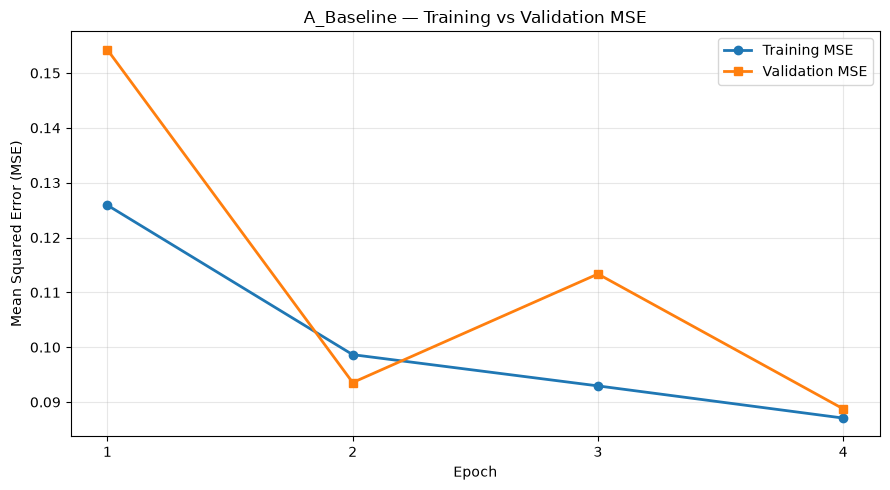

In [204]:
result_A, encoder_A, decoder_A = train_ablation_model(
    name="A_Baseline",
    spatial=False,
    sigmoid=False
)

print("\nExperiment A Results")
print("-" * 40)
print(f"Final Training MSE: {result_A['final_train_mse']:.6f}")
print(f"Final Validation MSE: {result_A['final_val_mse']:.6f}")
print(f"PSNR: {result_A['psnr']:.2f} dB")
print(f"Training Time: {result_A['training_minutes']:.2f} minutes")

# Display training and validation MSE chart
plot_ablation_results(result_A)

### 6.5 Experiment B — Spatial Features Only

B_Spatial | Epoch 1/4 | Train MSE: 0.102823 | Val MSE: 0.053410
B_Spatial | Epoch 2/4 | Train MSE: 0.050669 | Val MSE: 0.034570
B_Spatial | Epoch 3/4 | Train MSE: 0.040798 | Val MSE: 0.024009
B_Spatial | Epoch 4/4 | Train MSE: 0.033430 | Val MSE: 0.025825
--------------------------------------------------
B_Spatial completed
Final Validation MSE: 0.025825
PSNR: 15.88 dB
Training time: 12.65 minutes

Experiment B Results
----------------------------------------
Final Training MSE: 0.033430
Final Validation MSE: 0.025825
PSNR: 15.88 dB
Training Time: 12.65 minutes


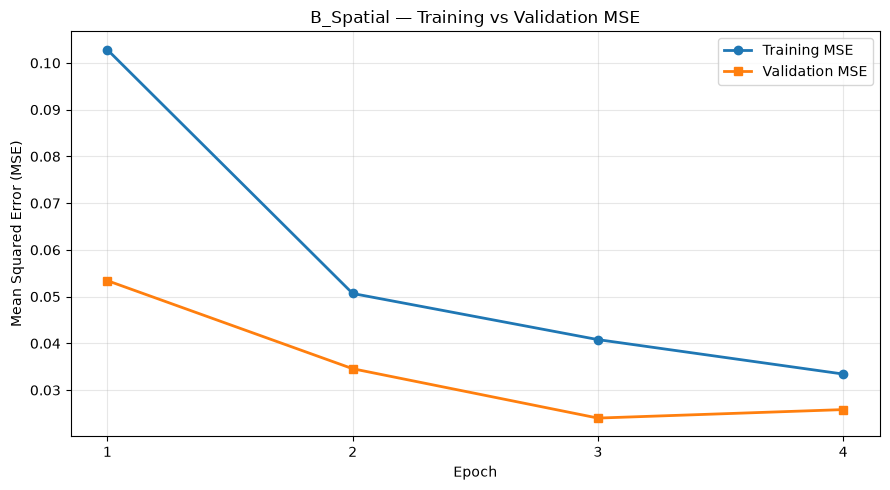

In [205]:
result_B, encoder_B, decoder_B = train_ablation_model(
    name="B_Spatial",
    spatial=True,
    sigmoid=False
)

print("\nExperiment B Results")
print("-" * 40)
print(f"Final Training MSE: {result_B['final_train_mse']:.6f}")
print(f"Final Validation MSE: {result_B['final_val_mse']:.6f}")
print(f"PSNR: {result_B['psnr']:.2f} dB")
print(f"Training Time: {result_B['training_minutes']:.2f} minutes")

plot_ablation_results(result_B)

### 6.6 Experiment C — Sigmoid Activation Only

C_Sigmoid | Epoch 1/4 | Train MSE: 0.082005 | Val MSE: 0.137939
C_Sigmoid | Epoch 2/4 | Train MSE: 0.073173 | Val MSE: 0.067166
C_Sigmoid | Epoch 3/4 | Train MSE: 0.068104 | Val MSE: 0.067656
C_Sigmoid | Epoch 4/4 | Train MSE: 0.064556 | Val MSE: 0.061400
--------------------------------------------------
C_Sigmoid completed
Final Validation MSE: 0.061400
PSNR: 12.12 dB
Training time: 12.31 minutes

Experiment C Results
----------------------------------------
Final Training MSE: 0.064556
Final Validation MSE: 0.061400
PSNR: 12.12 dB
Training Time: 12.31 minutes


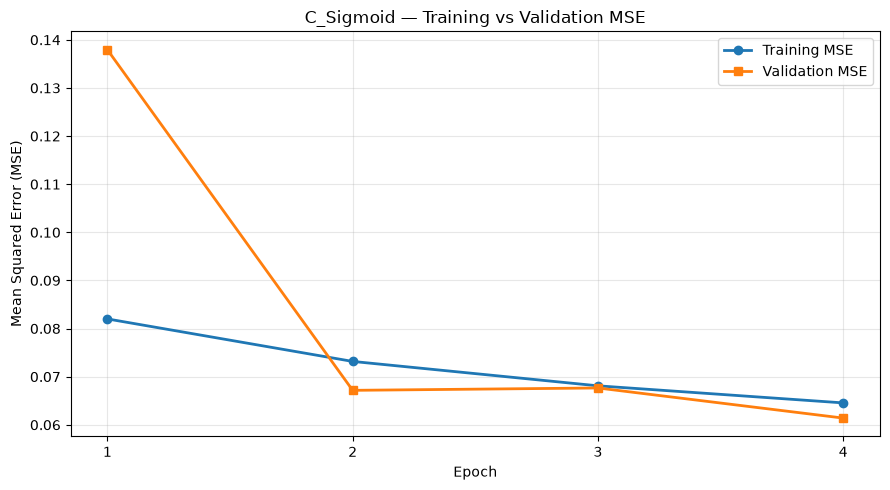

In [206]:
result_C, encoder_C, decoder_C = train_ablation_model(
    name="C_Sigmoid",
    spatial=False,
    sigmoid=True
)

print("\nExperiment C Results")
print("-" * 40)
print(f"Final Training MSE: {result_C['final_train_mse']:.6f}")
print(f"Final Validation MSE: {result_C['final_val_mse']:.6f}")
print(f"PSNR: {result_C['psnr']:.2f} dB")
print(f"Training Time: {result_C['training_minutes']:.2f} minutes")

plot_ablation_results(result_C)

### 6.7 Experiment D: Spatial + Sigmoid

D_Combined | Epoch 1/4 | Train MSE: 0.057017 | Val MSE: 0.023520
D_Combined | Epoch 2/4 | Train MSE: 0.031821 | Val MSE: 0.018051
D_Combined | Epoch 3/4 | Train MSE: 0.026392 | Val MSE: 0.016506
D_Combined | Epoch 4/4 | Train MSE: 0.023048 | Val MSE: 0.011006
--------------------------------------------------
D_Combined completed
Final Validation MSE: 0.011006
PSNR: 19.58 dB
Training time: 11.83 minutes

Experiment D Results
----------------------------------------
Final Training MSE: 0.023048
Final Validation MSE: 0.011006
PSNR: 19.58 dB
Training Time: 11.83 minutes


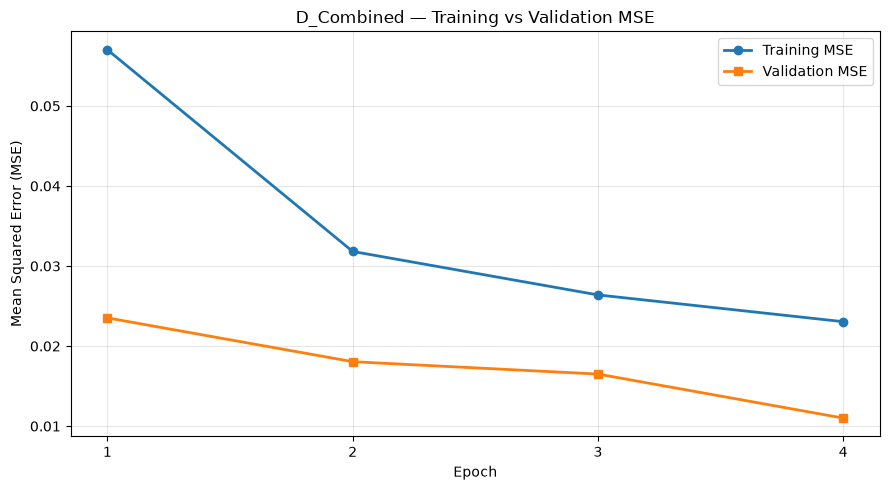

In [207]:
result_D, encoder_D, decoder_D = train_ablation_model(
    name="D_Combined",
    spatial=True,
    sigmoid=True
)

print("\nExperiment D Results")
print("-" * 40)
print(f"Final Training MSE: {result_D['final_train_mse']:.6f}")
print(f"Final Validation MSE: {result_D['final_val_mse']:.6f}")
print(f"PSNR: {result_D['psnr']:.2f} dB")
print(f"Training Time: {result_D['training_minutes']:.2f} minutes")

# Display training and validation MSE chart
plot_ablation_results(result_D)

### 6.8 — Full Ablation Study Comparison 

In [208]:
import pandas as pd
import matplotlib.pyplot as plt

# Collect results from all four experiments
ablation_results = [
    result_A,
    result_B,
    result_C,
    result_D
]

# Create comparison table
comparison_df = pd.DataFrame([
    {
        "Experiment": result["model"],
        "Spatial Features": "7x7" if result["spatial"] else "1x1",
        "Activation": "Sigmoid" if result["sigmoid"] else "ReLU",
        "Training MSE": result["final_train_mse"],
        "Validation MSE": result["final_val_mse"],
        "PSNR (dB)": result["psnr"],
        "Training Time (min)": result["training_minutes"]
    }
    for result in ablation_results
])

display(comparison_df.round(4))

,Experiment,Spatial Features,Activation,Training MSE,Validation MSE,PSNR (dB),Training Time (min)
0,A_Baseline,1x1,ReLU,0.0871,0.0888,10.5178,12.1147
1,B_Spatial,7x7,ReLU,0.0334,0.0258,15.8797,12.6486
2,C_Sigmoid,1x1,Sigmoid,0.0646,0.0614,12.1183,12.3101
3,D_Combined,7x7,Sigmoid,0.0230,0.0110,19.5838,11.8290


### 6.8.1 — Ablation Comparison Charts

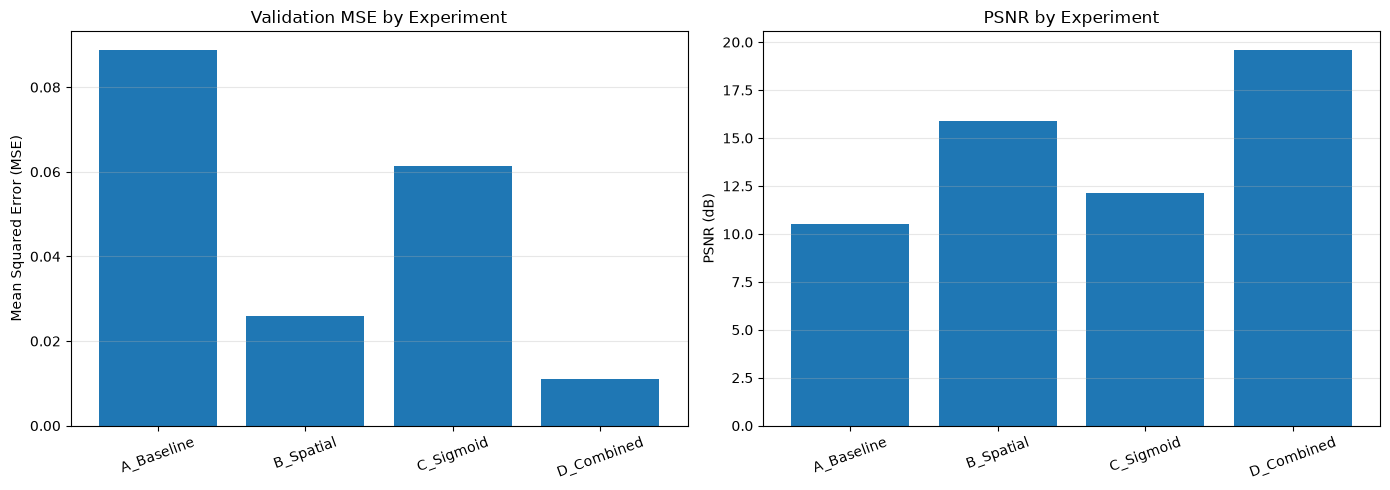

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

names = comparison_df["Experiment"]

# Validation MSE comparison
axes[0].bar(
    names,
    comparison_df["Validation MSE"]
)

axes[0].set_title("Validation MSE by Experiment")
axes[0].set_ylabel("Mean Squared Error (MSE)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)

# PSNR comparison
axes[1].bar(
    names,
    comparison_df["PSNR (dB)"]
)

axes[1].set_title("PSNR by Experiment")
axes[1].set_ylabel("PSNR (dB)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### 6.8.2 Calculate the improvement percentages

In [210]:
baseline_mse = result_A["final_val_mse"]
spatial_mse = result_B["final_val_mse"]
sigmoid_mse = result_C["final_val_mse"]
combined_mse = result_D["final_val_mse"]

def mse_reduction(reference, new):
    return ((reference - new) / reference) * 100

print("Ablation Study — Validation MSE Improvements")
print("-" * 50)

print(
    f"Spatial vs Baseline: "
    f"{mse_reduction(baseline_mse, spatial_mse):.2f}%"
)

print(
    f"Sigmoid vs Baseline: "
    f"{mse_reduction(baseline_mse, sigmoid_mse):.2f}%"
)

print(
    f"Combined vs Baseline: "
    f"{mse_reduction(baseline_mse, combined_mse):.2f}%"
)

print(
    f"Combined vs Spatial: "
    f"{mse_reduction(spatial_mse, combined_mse):.2f}%"
)

# Factorial interaction on the MSE scale
interaction = (
    combined_mse
    - spatial_mse
    - sigmoid_mse
    + baseline_mse
)

print(f"\nSpatial × Sigmoid interaction (MSE): {interaction:.6f}")

Ablation Study — Validation MSE Improvements
--------------------------------------------------
Spatial vs Baseline: 70.90%
Sigmoid vs Baseline: 30.82%
Combined vs Baseline: 87.60%
Combined vs Spatial: 57.38%

Spatial × Sigmoid interaction (MSE): 0.012540


### 6.9 Reconstruction Image Comparison

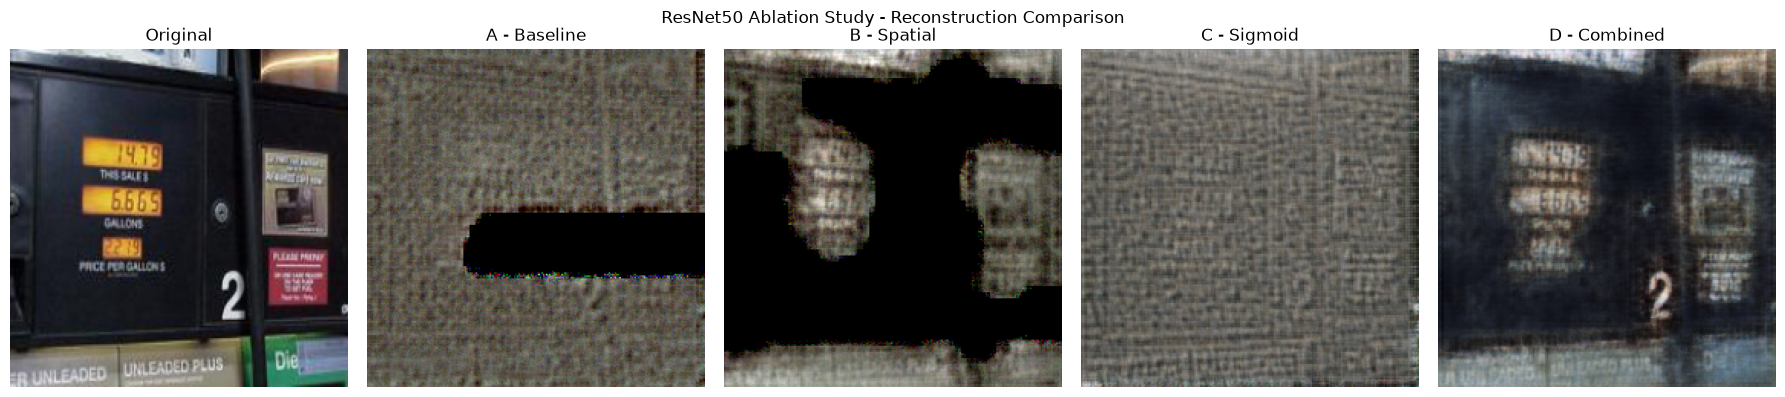

In [211]:
import matplotlib.pyplot as plt
import torch

# Use the same validation image for all models
image, _ = ablation_val_subset[0]

image_batch = image.unsqueeze(0).to(DEVICE)

models = [
    ("A - Baseline", encoder_A, decoder_A),
    ("B - Spatial", encoder_B, decoder_B),
    ("C - Sigmoid", encoder_C, decoder_C),
    ("D - Combined", encoder_D, decoder_D)
]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

# Original image
axes[0].imshow(image.permute(1, 2, 0).cpu().numpy())
axes[0].set_title("Original")
axes[0].axis("off")

# Reconstructed images
with torch.no_grad():

    for i, (name, encoder, decoder) in enumerate(models, start=1):

        encoder.eval()
        decoder.eval()

        features, indices = encoder(image_batch)
        reconstruction = decoder(features, indices)

        reconstruction = reconstruction.squeeze(0)
        reconstruction = reconstruction.permute(1, 2, 0)
        reconstruction = reconstruction.cpu().numpy()

        axes[i].imshow(reconstruction.clip(0, 1))
        axes[i].set_title(name)
        axes[i].axis("off")

plt.suptitle("ResNet50 Ablation Study - Reconstruction Comparison")
plt.tight_layout()
plt.show()

# 6.10 Final Ablation Study Summary

### 6.10.1 Objective
* Evaluate two ResNet50 autoencoder modifications: preserving 7 × 7 spatial features and replacing the final ReLU activation with Sigmoid.

* Test each modification separately and together using four configurations.

### 6.10.2 Experimental Results
| Experiment | Validation | MSE PSNR |
|:-----------|:-----------|:---------|
|A — Baseline| 0.088760 | 10.52 dB |
|B — Spatial Only | 0.025825 | 15.88 dB|
|C — Sigmoid Only | 0.061400 | 12.12 dB|
|D — Spatial + Sigmoid | 0.011006 | 19.58 dB|

### 6.10.3 Main Findings

* Preserving spatial information reduced validation MSE by 70.90% compared with the baseline.

* Replacing ReLU with Sigmoid reduced validation MSE by 30.82%.

* Combining both changes reduced validation MSE by 87.60%.

* Experiment D achieved the lowest validation MSE and highest PSNR.

* The reconstruction comparison showed that Experiment D preserved more recognizable image structure than the other configurations

### 6.10.4 Limitations

* Each configuration was trained once using random seed 42.

* Training used 2,000 images, 200 validation images, and four epochs.

* The study evaluated two architectural modifications, not every possible ResNet50 component.

* Additional random seeds and longer training could help determine whether the improvements are consistent.

### 6.10.5 Conclusion

* The four experiments completed a 2 × 2 factorial ablation of the selected architectural changes.

* Preserving spatial information produced the larger individual improvement.

* Combining spatial preservation with Sigmoid produced the best reconstruction performance under the tested conditions.

* Further experiments would be needed to establish how well the findings generalize.